# 3.1 K-Means

**K-Means** is one of the oldest and most widely used algorithms in **unsupervised learning**. Its goal is to partition a set of $n$ observations into $K$ disjoint groups (*clusters*) such that observations within the same group are as similar as possible, while groups are as different as possible from each other.

Unlike supervised learning, there is no target variable $y$: the algorithm only sees the feature matrix $X$ and must *discover* structure in the data. This is why, in the code below, `kmeans.fit(X1)` receives only `X1` and never the labels.

**Historical note.** The idea was proposed by Steinhaus (1956) and Lloyd (1957, published 1982) in the context of signal quantization; the name *k-means* was coined by MacQueen (1967). Its longevity is explained by its simplicity, scalability and interpretability.

**Typical applications:** customer segmentation, document grouping, image compression (color quantization), anomaly detection, vector quantization, and, more recently, grouping *embeddings* produced by deep learning and language models (e.g. topic discovery or building indices for semantic search).

Let $\mathcal{X} = \{\mathbf{x}_1, \dots, \mathbf{x}_n\}$, with $\mathbf{x}_i \in \mathbb{R}^p$. We seek a partition $\mathcal{C} = \{C_1, \dots, C_K\}$ and a set of **centroids** $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K \in \mathbb{R}^p$ that minimize the **within-cluster sum of squares (WCSS)**, also called **inertia** or **distortion**:

$$
J(\mathcal{C}, \boldsymbol{\mu}) \;=\; \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \left\lVert \mathbf{x}_i - \boldsymbol{\mu}_k \right\rVert_2^2
$$

Two key properties follow from this objective:

1. **Optimal centroid for a fixed partition.** If the clusters are fixed, $J$ is minimized when each centroid is the arithmetic mean of its points (hence the name *k-means*):
$$
\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i
$$

2. **Optimal assignment for fixed centroids.** If the centroids are fixed, $J$ is minimized by assigning each point to its nearest centroid:
$$
c(i) = \arg\min_{k \in \{1,\dots,K\}} \left\lVert \mathbf{x}_i - \boldsymbol{\mu}_k \right\rVert_2^2
$$

Finding the global minimum of $J$ is an **NP-hard** problem (even for $K=2$ in general dimension, or for general $K$ in the plane). For that reason, in practice we use a heuristic that alternates between these two properties.

> In scikit-learn, the value of $J$ for the fitted model is available in the attribute `kmeans.inertia_`.

### Lloyd's algorithm (standard K-Means)

The usual algorithm is an **alternating (coordinate-descent) optimization** procedure:

1. **Initialization:** choose $K$ initial centroids $\boldsymbol{\mu}_1^{(0)}, \dots, \boldsymbol{\mu}_K^{(0)}$.
2. **Assignment step (E-like step):** assign each observation to the cluster with the nearest centroid.
3. **Update step (M-like step):** recompute each centroid as the mean of the observations assigned to it.
4. **Repeat** steps 2–3 until the assignments no longer change (or the change in $J$ falls below a tolerance `tol`, or `max_iter` is reached).

**Convergence.** Each step can only decrease (or keep) $J$, and there is a finite number of possible partitions, so the algorithm always converges in a finite number of iterations. However, it converges to a **local minimum**, not necessarily the global one.

**Computational cost.** Each iteration costs $\mathcal{O}(n \cdot K \cdot p)$, which makes K-Means very efficient for large datasets. Variants such as **Mini-Batch K-Means** (Sculley, 2010) reduce the cost further by using random subsets of data in each iteration.

**Connection with other models.** K-Means can be seen as a limiting case of the EM algorithm for a **Gaussian Mixture Model (GMM)** with equal, spherical covariances ($\Sigma_k = \sigma^2 I$) when $\sigma^2 \to 0$, which turns the *soft* assignments of GMM into *hard* assignments.

### Initialization and the problem of local minima

Because the result depends on the starting centroids, a poor initialization can lead to suboptimal solutions (e.g. two centroids inside the same natural group and none in another). Two standard remedies:

- **K-Means++ (Arthur & Vassilvitskii, 2007):** the first centroid is drawn at random; each subsequent centroid is drawn with probability proportional to $D(\mathbf{x})^2$, the squared distance to the nearest centroid already chosen. This spreads the initial centroids and guarantees an expected solution within a factor $\mathcal{O}(\log K)$ of the optimum. It is the default in scikit-learn (`init='k-means++'`).
- **Multiple restarts:** run the algorithm several times with different seeds and keep the solution with the lowest inertia. In scikit-learn this is controlled by `n_init` (with `n_init='auto'`, 1 run is used with k-means++ and 10 with random initialization).

The parameter `random_state` fixes the random seed so that results are **reproducible**, which is essential in teaching and research contexts.

### Choosing the number of clusters $K$

$K$ is a **hyperparameter**: the algorithm does not learn it. Moreover, inertia always decreases as $K$ grows (in the limit $K=n$, $J=0$), so it cannot be minimized directly to choose $K$. Common criteria:

| Method | Idea | Interpretation |
|---|---|---|
| **Elbow method** | Plot $J(K)$ against $K$ | Choose the $K$ at which the curve "bends": additional clusters yield marginal reductions of inertia |
| **Silhouette coefficient** (Rousseeuw, 1987) | For each point, $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$, where $a(i)$ is the mean distance to its own cluster and $b(i)$ the mean distance to the nearest other cluster | $s \in [-1, 1]$; choose $K$ that maximizes the mean silhouette |
| **Gap statistic** (Tibshirani et al., 2001) | Compare $\log J(K)$ with its expected value under a null reference distribution (uniform data) | Choose the smallest $K$ with a significant gap |
| **Information criteria / domain knowledge** | BIC/AIC under probabilistic models, or business/scientific requirements | Often the most relevant criterion in applied settings |

In this notebook we will apply the **elbow method** using `kmeans.inertia_`.

### Assumptions, limitations and good practices

K-Means implicitly assumes clusters that are:

- **Convex and approximately spherical (isotropic)**, because it uses Euclidean distance to a single centroid. The decision boundaries between clusters are **linear** (they form a **Voronoi tessellation** of the space), so it struggles with elongated, concentric or non-convex shapes (e.g. "moons" or rings).
- **Of similar size and density**: large or dispersed clusters may be split, and small ones absorbed.

Other practical considerations:

- **Feature scaling:** since it is distance-based, variables with larger ranges dominate. Standardizing (`StandardScaler`) is usually necessary.
- **Sensitivity to outliers:** the mean is not robust; alternatives such as **K-Medoids (PAM)** or **K-Medians** mitigate this.
- **Numerical data only:** for categorical variables use **K-Modes** or **K-Prototypes**.
- **High dimensionality:** Euclidean distances lose discriminative power (*curse of dimensionality*); dimensionality reduction (PCA, UMAP) before clustering is often helpful.
- **Alternatives** for complex structures: **DBSCAN/HDBSCAN** (density-based, arbitrary shapes, detects noise), **Gaussian Mixture Models** (soft assignments, elliptical clusters), **spectral clustering** and **hierarchical clustering**.

Finally, clustering is an **exploratory** tool: the groups found are a hypothesis about the structure of the data and must be validated with domain knowledge. K-Means will *always* return $K$ clusters, even when the data contain no real group structure.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
%matplotlib inline

#### Generate simulated data and visualize:

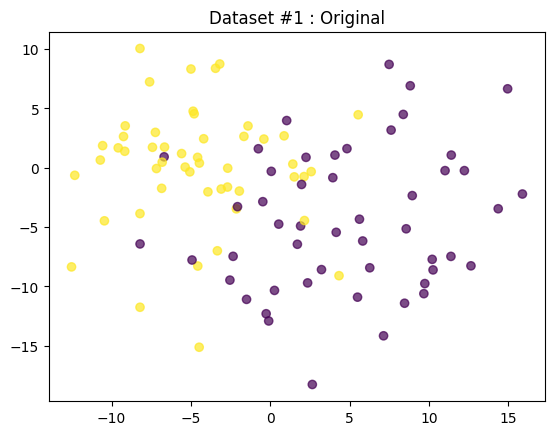

In [4]:
# Dataset #1.
X1, label1 = make_blobs(n_samples=100, n_features=2, centers=2, cluster_std = 5, random_state=123)
plt.scatter(X1[:,0],X1[:,1], c= label1, alpha=0.7 )
plt.title('Dataset #1 : Original')
plt.show()

In [5]:
label1

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0])

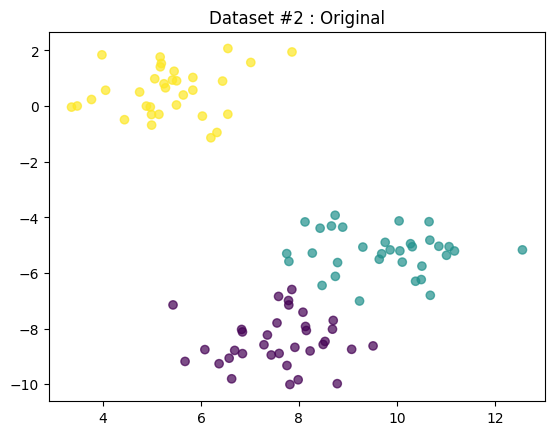

In [6]:
# Dataset #2
X2, label2 = make_blobs(n_samples=100, n_features=2, centers=3, cluster_std = 1, random_state=321)
plt.scatter(X2[:,0],X2[:,1], c= label2, alpha=0.7 )
plt.title('Dataset #2 : Original')
plt.show()

In [7]:
label2

array([0, 2, 1, 0, 0, 2, 0, 0, 1, 2, 1, 0, 0, 1, 2, 2, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 1, 0, 1, 0, 2, 2, 2, 1, 2, 1, 0, 0, 2, 0, 0, 1, 2, 0,
       1, 1, 0, 2, 0, 2, 1, 1, 0, 1, 2, 0, 2, 1, 2, 1, 1, 0, 2, 1, 0, 2,
       1, 0, 1, 1, 1, 0, 2, 0, 1, 0, 2, 0, 1, 1, 2, 0, 0, 1, 2, 0, 0, 2,
       2, 2, 2, 1, 0, 1, 0, 0, 0, 0, 1, 2])

#### Apply k-means clustering and visualize:

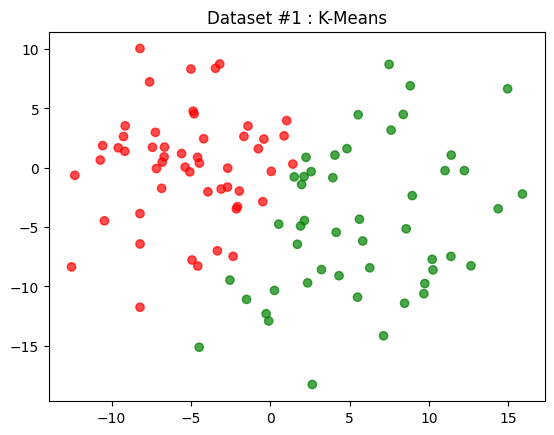

In [8]:
# Dataset #1 and two clusters.
kmeans = KMeans(n_clusters=2,random_state=123, n_init='auto')                 # kmeans object for 2 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X1)                                                 # Unsupervised learning => Only X1.    
myColors = {0:'red',1:'green', 2:'blue'}                       # Define a color palette: 0~2.
plt.scatter(X1[:,0],X1[:,1], c= pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 )   
plt.title('Dataset #1 : K-Means')
plt.show()

In [12]:
kmeans.inertia_

4595.909596134363

Text(0.5, 1.0, 'Elbow curve')

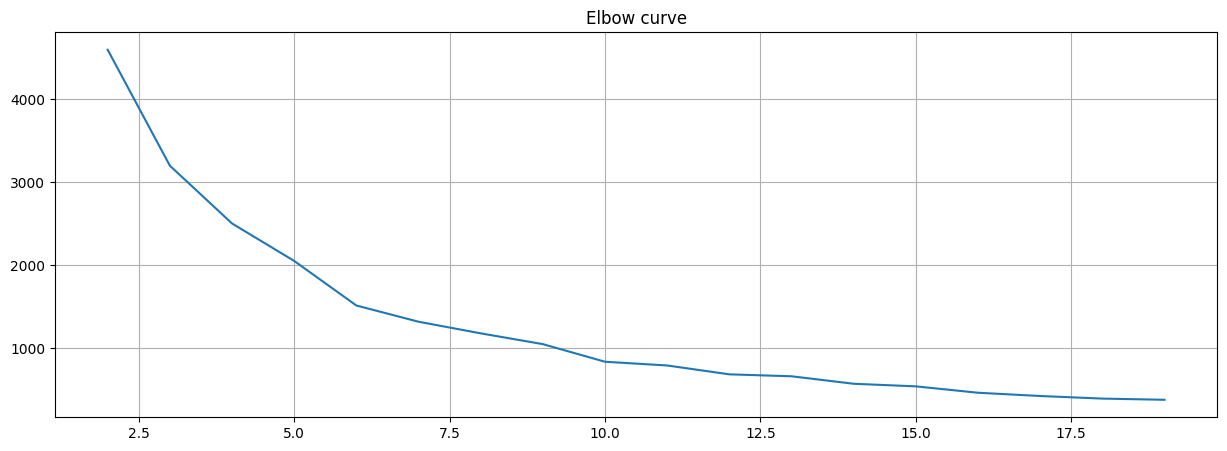

In [13]:
distorsions = []
for k in range(2, 20):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X1)
    distorsions.append(kmeans.inertia_)

fig = plt.figure(figsize=(15, 5))
plt.plot(range(2, 20), distorsions)
plt.grid(True)
plt.title('Elbow curve')

In [ ]:
kmeans.labels_

array([2, 1, 0, 2, 2, 1, 2, 2, 0, 1, 0, 2, 2, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 2, 0, 2, 1, 1, 1, 0, 1, 0, 2, 2, 1, 2, 2, 0, 1, 2,
       0, 0, 2, 1, 2, 1, 0, 0, 2, 0, 1, 2, 1, 0, 1, 0, 0, 2, 1, 0, 2, 1,
       0, 2, 0, 0, 0, 2, 1, 2, 0, 2, 1, 2, 0, 0, 1, 2, 2, 0, 1, 2, 2, 1,
       1, 1, 1, 0, 2, 0, 2, 2, 2, 2, 0, 1], dtype=int32)

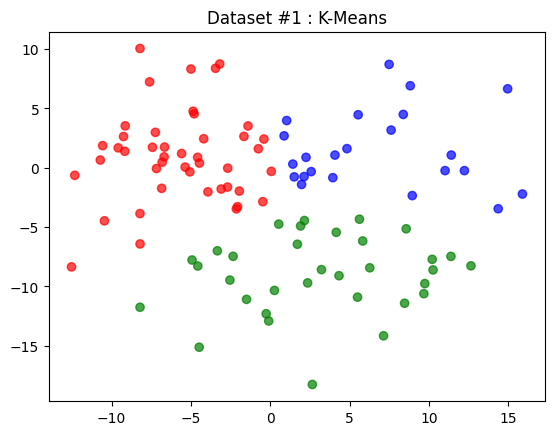

In [18]:
# Dataset #1 and three clusters.
kmeans = KMeans(n_clusters=3,random_state=123, n_init='auto')                 # kmeans object for 3 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X1)                                                 # Unsupervised learning => Only X1.    
myColors = {0:'red',1:'green', 2:'blue'}                       # Define a color palette: 0~3.
plt.scatter(X1[:,0],X1[:,1], c= pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 ) 
plt.title('Dataset #1 : K-Means')
plt.show()

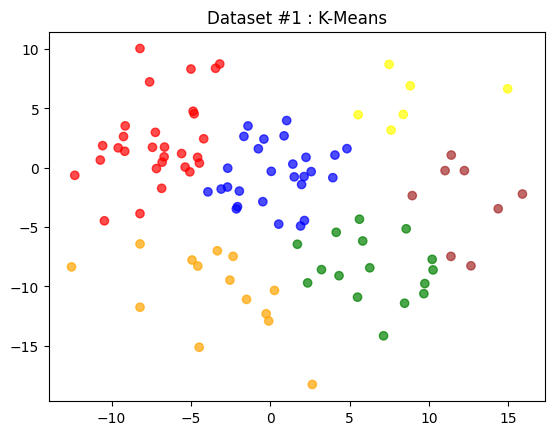

In [17]:
# Dataset #1 and three clusters.
kmeans = KMeans(n_clusters=6,random_state=123, n_init='auto')                 # kmeans object for 3 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X1)                                                 # Unsupervised learning => Only X1.    
myColors = {0:'red',1:'green', 2:'blue', 3: 'yellow', 4: 'brown', 5:'orange'}                       # Define a color palette: 0~3.
plt.scatter(X1[:,0],X1[:,1], c= pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 ) 
plt.title('Dataset #1 : K-Means')
plt.show()

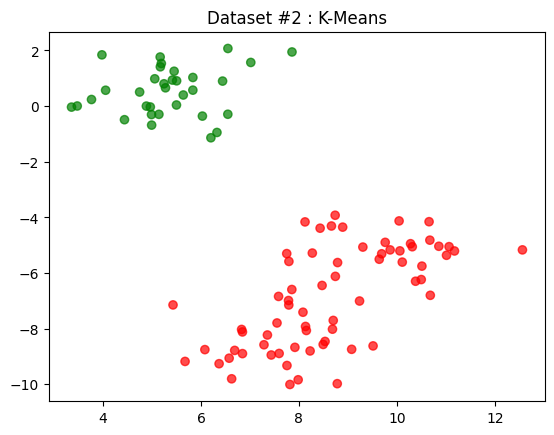

In [ ]:
# Dataset #2 and two clusters.
kmeans = KMeans(n_clusters=2,random_state=123, n_init='auto')                 # kmeans object for 2 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X2)                                                 # Unsupervised learning => Only X2.    
plt.scatter(X2[:,0],X2[:,1], c= pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 )  
plt.title('Dataset #2 : K-Means')
plt.show()

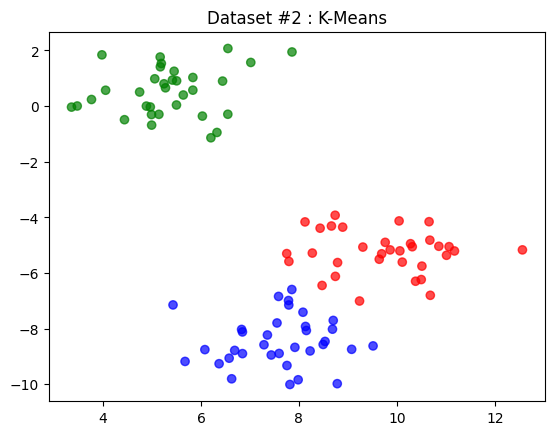

In [ ]:
# Dataset #2 and three clusters.
kmeans = KMeans(n_clusters=3, random_state=123, n_init='auto')                # kmeans object for 3 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X2)                                                 # Unsupervised learning => Only X2.    
plt.scatter(X2[:,0],X2[:,1], c= pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 )  
plt.title('Dataset #2 : K-Means')
plt.show()

NOTE: k means clusters have linear boundaries. The clustering result may reveal the existing structure, but this is not always guaranteed.